In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models , optimizers
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_digits
from tensorflow.keras.models import Sequential

import matplotlib.pyplot as plt
import numpy as np

In [2]:
digit = load_digits()

In [3]:
digit.keys()

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])

In [4]:
X = digit["data"].reshape(-1,8,8,1).astype('float') / 16.0
Y = digit["target"]

In [5]:
train_X, test_X, train_Y, test_Y = train_test_split(X, Y, test_size=0.2, random_state=42)

In [6]:
print("Train data shape:", train_X.shape)
print("Train labels shape:", train_Y.shape)

print("Test data shape:", test_X.shape)
print("Test labels shape:", test_Y.shape)

Train data shape: (1437, 8, 8, 1)
Train labels shape: (1437,)
Test data shape: (360, 8, 8, 1)
Test labels shape: (360,)


In [7]:
import Utility  as util

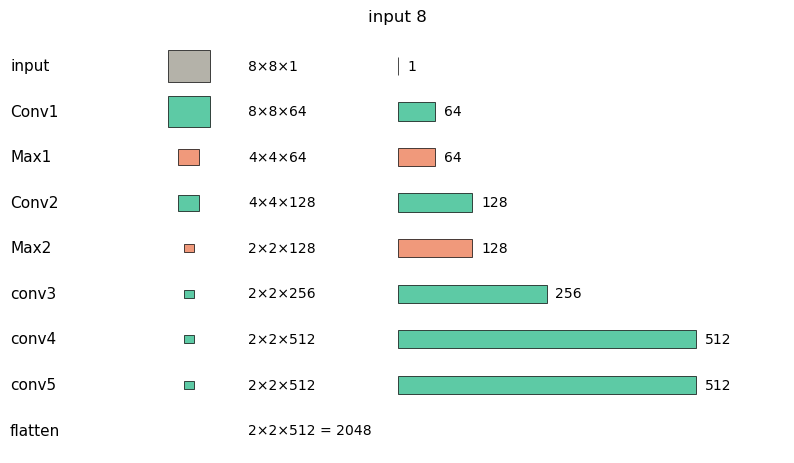

In [8]:
calc = (
    util.ShapeCalculator(8)
    .conv("Conv1", kernel=2, pad="same", filters=64)
    .pool("Max1", 2)
    .conv("Conv2", kernel=2, pad="same", filters=128)
    .pool("Max2", 2)
    .conv("conv3", kernel=3, pad="same", filters=256)
    .conv("conv4", kernel=3, pad="same", filters=512)
    .conv("conv5", kernel=3, pad="same", filters=512)
)

calc.plot()

In [9]:
model = Sequential([
    layers.Input(shape=(8, 8, 1)),
    layers.Conv2D(64, kernel_size=2, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(128, kernel_size=2, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(256, kernel_size=3, padding="same", activation="relu"),
    layers.Conv2D(512, kernel_size=3, padding="same", activation="relu"),
    layers.Conv2D(512, kernel_size=3, padding="same", activation="relu"),
    layers.Flatten(),
    
    layers.Dense(4096, activation="relu"),
    layers.Dense(4096, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

In [10]:
model.compile(optimizer= 'adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [11]:
model.fit(train_X, train_Y, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 321ms/step - accuracy: 0.1889 - loss: 2.0571 - val_accuracy: 0.1979 - val_loss: 1.9940
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 11s 300ms/step - accuracy: 0.3159 - loss: 1.5700 - val_accuracy: 0.3715 - val_loss: 1.4856
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 11s 300ms/step - accuracy: 0.4952 - loss: 1.2080 - val_accuracy: 0.6424 - val_loss: 1.0855
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 11s 294ms/step - accuracy: 0.7154 - loss: 0.7431 - val_accuracy: 0.8160 - val_loss: 0.5320
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 11s 298ms/step - accuracy: 0.8259 - loss: 0.4747 - val_accuracy: 0.8542 - val_loss: 0.5452
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 11s 301ms/step - accuracy: 0.8825 - loss: 0.3187 - val_accuracy: 0.8993 - val_loss: 0.3595
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 11s 300ms/step - accuracy: 0.9121 - loss: 0.2272 - val_accuracy: 0.8958 - val_loss: 0.5003
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 11s 300ms/step - accuracy: 0.9530 - loss: 0.1690 - val_accu

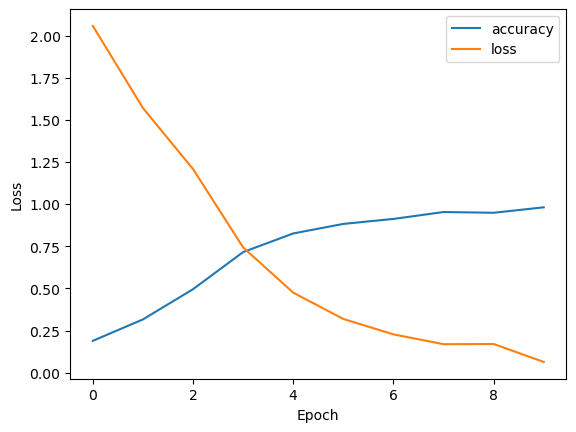

In [12]:
plt.plot(model.history.history['accuracy'], label='accuracy')
plt.plot(model.history.history['loss'], label='loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()